# **Clinical Data – project, Week 2 | Machine Learning Pipeline for Feature Selection and Predictive Modeling**

by FANI TZINA - MEI Master's program, AUTH

Load libraries; if these libraries are not found, we first install them with !pip install *libraryname*

In [ ]:
import numpy as np
import pandas as pd
import io
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import StandardScaler

import warnings
warnings.filterwarnings('ignore')

In [ ]:
# Load your CSV file
df = pd.read_csv('/content/heart.csv')

# Feature names (all column names)
feat = df.columns.tolist()

print(df.head())
print("\nFeatures:", feat)

   Age Sex ChestPainType  RestingBP  Cholesterol  FastingBS RestingECG  MaxHR  \
0   40   M           ATA        140          289          0     Normal    172   
1   49   F           NAP        160          180          0     Normal    156   
2   37   M           ATA        130          283          0         ST     98   
3   48   F           ASY        138          214          0     Normal    108   
4   54   M           NAP        150          195          0     Normal    122   

  ExerciseAngina  Oldpeak ST_Slope  HeartDisease  
0              N      0.0       Up             0  
1              N      1.0     Flat             1  
2              N      0.0       Up             0  
3              Y      1.5     Flat             1  
4              N      0.0       Up             0  

Features: ['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS', 'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope', 'HeartDisease']


Check for missing values:

In [ ]:
print(df.shape)
print('NULL: ',df.isnull().sum())
print('NaN: ', df.isna().sum())

df.dropna(inplace=True)
print("Dataset's shape: ",df.shape)

(918, 12)
NULL:  Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64
NaN:  Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64
Dataset's shape:  (918, 12)


Thankfully, there are no missing values in our dataset. We also see that our dataset consists of 918 patients and 12 features.

Turn categorical features into numerical values.

In [ ]:
from sklearn.preprocessing import LabelEncoder
encoder = LabelEncoder()

for col in ['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope']:
    df[col] = encoder.fit_transform(df[col])
    print(encoder.classes_)

[0 1]
[0 1 2 3]
[0 1 2]
[0 1]
[0 1 2]


**APA**:
Sex: [F M] --> [0 1]

ChestPainType: ['ASY' 'ATA' 'NAP' 'TA'] --> [0 1 2 3]

RestingECG: ['LVH' 'Normal' 'ST'] --> [0 1 2]

ExerciseAngina: ['N' 'Y'] --> [0 1]

ST_Slope: ['Down' 'Flat' 'Up'] --> [0 1 2]

# Explore the dataset

In [ ]:
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,1,1,140,289,0,1,172,0,0.0,2,0
1,49,0,2,160,180,0,1,156,0,1.0,1,1
2,37,1,1,130,283,0,2,98,0,0.0,2,0
3,48,0,0,138,214,0,1,108,1,1.5,1,1
4,54,1,2,150,195,0,1,122,0,0.0,2,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    int64  
 2   ChestPainType   918 non-null    int64  
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    int64  
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    int64  
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    int64  
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(11)
memory usage: 86.2 KB


In [ ]:
df.describe()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,0.789760,0.781046,132.396514,198.799564,0.233115,0.989107,136.809368,0.404139,0.887364,1.361656,0.553377
std,9.432617,0.407701,0.956519,18.514154,109.384145,0.423046,0.631671,25.460334,0.490992,1.066570,0.607056,0.497414
min,28.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,60.000000,0.000000,-2.600000,0.000000,0.000000
25%,47.000000,1.000000,0.000000,120.000000,173.250000,0.000000,1.000000,120.000000,0.000000,0.000000,1.000000,0.000000
50%,54.000000,1.000000,0.000000,130.000000,223.000000,0.000000,1.000000,138.000000,0.000000,0.600000,1.000000,1.000000
75%,60.000000,1.000000,2.000000,140.000000,267.000000,0.000000,1.000000,156.000000,1.000000,1.500000,2.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,603.000000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,1.000000


**STANDARIZATION**

I have binary/categorical features mixed with continuous features, so: it’s better to standardize only the continuous features to avoid distorting binary variables.

In [ ]:
columns = ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']

#standardize the columns
standard_scaler = StandardScaler()
scaled = standard_scaler.fit_transform(df[columns])

df.describe()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,0.789760,0.781046,132.396514,198.799564,0.233115,0.989107,136.809368,0.404139,0.887364,1.361656,0.553377
std,9.432617,0.407701,0.956519,18.514154,109.384145,0.423046,0.631671,25.460334,0.490992,1.066570,0.607056,0.497414
min,28.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,60.000000,0.000000,-2.600000,0.000000,0.000000
25%,47.000000,1.000000,0.000000,120.000000,173.250000,0.000000,1.000000,120.000000,0.000000,0.000000,1.000000,0.000000
50%,54.000000,1.000000,0.000000,130.000000,223.000000,0.000000,1.000000,138.000000,0.000000,0.600000,1.000000,1.000000
75%,60.000000,1.000000,2.000000,140.000000,267.000000,0.000000,1.000000,156.000000,1.000000,1.500000,2.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,603.000000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,1.000000


In [ ]:
#split data into features and target
X = df.drop(columns = ['HeartDisease']) #features
y = df['HeartDisease'] # target

#print(X.columns)
#print(y)

target
1         508
0         410
Name: count, dtype: int64


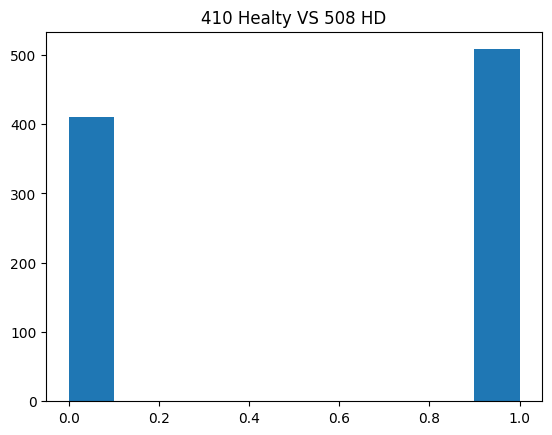

In [ ]:
target = 'HeartDisease'
classes = pd.DataFrame()
classes['target'] = df[target]
print(classes.value_counts())
plt.hist(y)
plt.title("410 Healty VS 508 HD") # 0: healthy , 1: HD
plt.show()

> Is the dataset imbalanced?
ANSWER:

    Total patients = 508 + 410 = 918
    Class 0 (no heart disease) = 508 → 55.3%
    Class 1 (heart disease) = 410 → 45.5%

Here, 55/45 is **pretty balanced**, because the difference between classes is small.

The two groups: Features (X) & Target label (y)

In [ ]:
# define our target
target = "HeartDisease"
X = df.drop(columns=[target])   # features
y = df[target]                  # target label

print('Shape of X: ', X.shape)
print('Shape of y: ', y.shape)

df_H = X[y == 0] # Healthy
df_HD =X[y== 1] # Not Healthy - heart disease (HD)

print('Shape of Not_Healthy: ', df_H.shape)
print('Shape of Healthy: ', df_HD.shape)

import warnings
warnings.filterwarnings('ignore')

Shape of X:  (918, 11)
Shape of y:  (918,)
Shape of Not_Healthy:  (410, 11)
Shape of Healthy:  (508, 11)


# *Feature* Selection - filter methods

Removing features with low variance

VarianceThreshold is a simple baseline approach to feature selection. It removes all features whose variance doesn’t meet some threshold

In [ ]:
from sklearn.feature_selection import VarianceThreshold
sel = VarianceThreshold(threshold=(.8 * (1 - .8)))
sel.fit_transform(X)

print('Shape of X: ', X.shape)
print('Shape of y: ', y.shape)


Shape of X:  (918, 11)
Shape of y:  (918,)


# Statistical Significance of features

**The p-value threshold**:
p-value is a number we choose that if crossed we can conclude an hypothesis is true. Everything under this threshold is rejected.

> Akolouthei to ANOVA F-test: using SelectKBest to check whether each continuous feature is significantly associated with the target variable, HeartDisease. The key output here is the p-value for each feature.

* p-value indicates the probability of observing the data, assuming there is no real relationship between the feature and the target (null hypothesis).

A small p-value (< 0.05) means you can reject the null hypothesis H0, suggesting the feature is significantly related to heart disease.

In [ ]:
from sklearn.feature_selection import SelectKBest, f_classif

X_cont = df[['Age','MaxHR','Oldpeak','RestingBP','Cholesterol','FastingBS']]
y = df['HeartDisease']

selector = SelectKBest(score_func=f_classif, k='all')
selector.fit(X_cont, y)

for i, col in enumerate(X_cont.columns):
    print(col, "p-value:", selector.pvalues_[i])

Age p-value: 3.007953240050356e-18
MaxHR p-value: 1.1377859840299948e-36
Oldpeak p-value: 2.390772424058019e-37
RestingBP p-value: 0.0010953145851683456
Cholesterol p-value: 9.308308883530943e-13
FastingBS p-value: 1.75359801032953e-16


Based on results above, we reliase that all p-values are << 0.05, meaning that all 6 continuous features show a statistically significant relationship with heart disease in our dataset.
More specifically, **MaxHR, Oldpeak, and FastingBS** have extremely small p-values, indicating they are strong predictors. **RestingBP** is still significant, but less strongly associated compared to other features.

**T-Test and kruskall-wallis**

We drop the features not different between the two classes. This is a filter method for feature selection:

> p ≤ 0.05 → reject H₀ → feature is significantly different → keep it

> p > 0.05 → fail to reject H₀ → drop it

> H0 = to MaxHR den diaferei apo aytoys poy exoyn heartdisease k apo tous igeiis




In [ ]:
# H0 = to MaxHR den diaferei apo aytoys poy exoyn heartdisease k apo tous igeiis
from scipy.stats import ttest_ind

feature = 'MaxHR'
group0 = df[df['HeartDisease']==0][feature]
group1 = df[df['HeartDisease']==1][feature]

stat, p = ttest_ind(group0, group1)
print(f"{feature}: p-value = {p}")

MaxHR: p-value = 1.1377859840278097e-36


In conclusion, here, p-value <<< 0.05 and so: (1) MaxHR is significantly different between the classes (healthy patients and the heart-diseased ones), and (b) this variable is informative for my model and so I must maintain it in my dataset.

In [ ]:
from scipy.stats import kruskal

feature = 'Oldpeak'
group0 = df[df['HeartDisease']==0][feature]
group1 = df[df['HeartDisease']==1][feature]

stat, p = kruskal(group0, group1)
print(f"{feature}: p-value = {p}")

Oldpeak: p-value = 6.756660322294789e-37



> H₀ = The distribution of Oldpeak is the same across patients with and without heart disease.

Here: p-value <<< 0.05 ---> **Oldpeak distribution is significantly different between the two classes.**

-------------------------------------------

**EXTRAS**

In [ ]:
### GIA THN FENIA - GIA MELETH -- T-TEST ('H KRUSKAL) // LYSI 1
## GENIKA: EPEIDI MPERDEYOMAI, THA VRW ANALAYTIKA GIA KATHE COLUMN POIO EINAI TO P-VALUE
# GIA NA KATALAVW POIA STOIXEIA MOY DINOYN PPLIROFORIES SIMANTIKES GIA TO MONTELO MOY -> ARA POIES PREPEI NA KRATISW K POIES MPORW NA DIWKSW.

# TO PARAKATW TO KANW GIA NA EPIVEVAIWSW POIES STHLES EXOYN KALO P-VALUE
# WSTE NA KSEXORISW POIES STILES MENOYN K POIES EINAI AXRHSTES

#**THIMIZW: AN P-VALUE < 0.05 ----> KEEP**
#**ALLIWS, DITCH!**

target = 'HeartDisease'

# Identify continuous features (numeric and not target)
continuous_features = df.select_dtypes(include=['int64','float64']).columns.tolist()
continuous_features.remove(target)

# Dictionaries to store results
feature_pvalues = {}
keep_features = []
drop_features = []

# Loop over each continuous feature
for feature in continuous_features:
    group0 = df[df[target] == 0][feature]
    group1 = df[df[target] == 1][feature]

    # Option 1: T-Test (parametric)
    stat, p = ttest_ind(group0, group1, equal_var=False)

    feature_pvalues[feature] = p

    # Decide whether to keep or drop
    if p <= 0.05:
        keep_features.append(feature)
    else:
        drop_features.append(feature)

# Convert results to DataFrame for nice display
results = pd.DataFrame({
    'Feature': continuous_features,
    'p-value': [feature_pvalues[f] for f in continuous_features],
    'Keep': [f in keep_features for f in continuous_features]
})

print("Features to keep:\n", keep_features)
print("\nFeatures to drop:\n", drop_features)
print("\nAll results:\n", results.sort_values('p-value')) # SORTARE APO TA POIO KALA ( <<< 0.05) p-values EWS TA PIO "ASYMANTA" (~ 0.05)

Features to keep:
 ['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope']

Features to drop:
 ['RestingECG']

All results:
            Feature       p-value   Keep
10        ST_Slope  2.100101e-75   True
8   ExerciseAngina  3.349121e-61   True
9          Oldpeak  1.902722e-40   True
7            MaxHR  1.430637e-36   True
2    ChestPainType  6.534084e-34   True
1              Sex  2.789309e-19   True
0              Age  6.348337e-18   True
5        FastingBS  9.852286e-18   True
4      Cholesterol  6.481236e-14   True
3        RestingBP  8.732265e-04   True
6       RestingECG  7.847209e-02  False


In [ ]:
import numpy as np
from scipy.stats import ttest_ind
from scipy.stats import kruskal

colsX = X.columns
print(colsX)
for i in colsX:
  v1=df_H.loc[:,i]
  v2=df_HD.loc[:,i]
  #t, p = ttest_ind(v1, v2)
  t, p = kruskal(v1,v2)
  if (p >= 0.05) :
    print(i,t,p,np.mean(v1),np.mean(v2))
    X = X.drop([i], axis=1)

Index(['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS',
       'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope'],
      dtype='object')
RestingECG 2.9682664029863255 0.08491280474440521 0.948780487804878 1.0216535433070866


In [ ]:
print('Shape of X: ', X.shape)
print('Shape of y: ', y.shape)

Shape of X:  (918, 10)
Shape of y:  (918,)


In [ ]:
X0=X

# *Feature* Selection wrapper methods

Recursive feature elimination: Selects features by recursively considering smaller and smaller sets of features.

https://scikit-learn.org/stable/modules/generated/sklearn.feature_selection.RFE.html#sklearn.feature_selection.RFE



SVC - Support Vector Classifier; a sub-group of SVM

In [ ]:
# GIA MELETI THS FENIAS - TO IDIO APOTELESMA PAIRNW ME linear SVM KAI Logistic Regression, KATHWS APODEIXTIKE GIA 3H FORA SYNEXOMENA OTI
# H STHLH RestingBP EINAI AXRHSTH GIA TO MONTELO MOY. +++ blepe apendix katw katw
from sklearn.svm import SVC
from sklearn.feature_selection import RFE
import matplotlib.pyplot as plt

# Create the RFE object and rank each pixel
svc = SVC(kernel="linear", C=1)
selector  = RFE(estimator=svc, n_features_to_select=10)
selector.fit(X, y)

filter = selector.support_
ranking = selector.ranking_

features = X.columns
print("All features:")
print(features)

print("Selected features:")
print(features[filter])

#X=X[columns=features[filter]]
X1=X[features[filter]]

All features:
Index(['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS',
       'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope'],
      dtype='object')
Selected features:
Index(['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS',
       'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope'],
      dtype='object')


L1-based feature selection ( L1 norm)

https://scikit-learn.org/stable/modules/generated/sklearn.feature_selection.SelectFromModel.html#sklearn.feature_selection.SelectFromModel


https://scikit-learn.org/stable/modules/generated/sklearn.svm.LinearSVC.html


In [ ]:
from sklearn.svm import LinearSVC
from sklearn.feature_selection import SelectFromModel

print(X.shape)
lsvc = LinearSVC(C=0.1, penalty="l1", dual=False).fit(X, y)
model = SelectFromModel(lsvc, prefit=True)
X_new = model.transform(X)
print(X_new.shape)

feature_names = X.columns
feature_names = feature_names[model.get_support()]
print("selected features:")
print(feature_names)

X2=X[feature_names]

(918, 10)
(918, 10)
selected features:
Index(['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS',
       'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope'],
      dtype='object')


**Tree-based feature selection**

https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.ExtraTreesClassifier.html

In [ ]:
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.feature_selection import SelectFromModel

print(X.shape)
print(X.columns)
clf = ExtraTreesClassifier(n_estimators=50)
clf = clf.fit(X, y)
print(clf.feature_importances_)
model = SelectFromModel(clf, prefit=True)

X_new = model.transform(X)
print(X_new.shape)

feature_names = X.columns
feature_names = feature_names[model.get_support()]
print("selected features:")
print(feature_names)

X3=X[feature_names]


(918, 10)
Index(['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS',
       'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope'],
      dtype='object')
[0.0727823  0.05555037 0.09701837 0.07290768 0.10549676 0.04310748
 0.10371406 0.13263796 0.10154105 0.21524397]
(918, 5)
selected features:
Index(['Cholesterol', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope'], dtype='object')


From the results shown above, we see that there are a few high scores while the biggest one, equal to 0.21524397, belongs to ST_Slope. In conclusion, the most important values indicate the most important features for the predictive model of the target (HeartDisease), and these features are shown below in descending order:

**ST_Slope > ExerciseAngina > ChestPainType > Cholesterol**

# Machine Learning in Python - Sklearn/ scikit-learn Python Library

see
https://scikit-learn.org/stable/

complete user guide: https://scikit-learn.org/0.21/user_guide.html

Check
https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html

# Available classifiers

RF
SVM
XGBOOST




In [ ]:
X2.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,MaxHR,ExerciseAngina,Oldpeak,ST_Slope
0,40,1,1,140,289,0,172,0,0.0,2
1,49,0,2,160,180,0,156,0,1.0,1
2,37,1,1,130,283,0,98,0,0.0,2
3,48,0,0,138,214,0,108,1,1.5,1
4,54,1,2,150,195,0,122,0,0.0,2


In [ ]:
from xgboost import XGBClassifier
X_train, X_test, y_train, y_test = train_test_split(X2, y, test_size=0.3, random_state=10)
print(X_train.shape)

xgb = XGBClassifier(n_estimators=100, learning_rate=0.1, random_state=42)
xgb.fit(X_train, y_train)
y_pred = xgb.predict(X_test)

(642, 10)


# Model selection and evaluation

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split( X2, y, test_size=0.3, random_state=10)
print(X_train.shape)

(642, 10)


In [ ]:
print(y_train.shape)

(642,)


HeartDisease
1    359
0    283
Name: count, dtype: int64


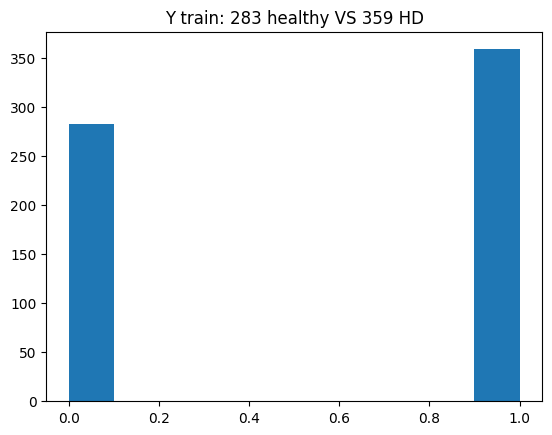

In [ ]:
print(y_train.value_counts())
plt.hist(y_train)
plt.title("Y train: 283 healthy VS 359 HD")
plt.show()

generate extra data for the minority class

In [ ]:
if(0):
  !pip install imbalanced-learn

  from imblearn.over_sampling import SMOTE
  from imblearn.under_sampling import RandomUnderSampler
  from imblearn.pipeline import Pipeline

  print(X_train.shape)
  X_train.describe()

  from imblearn.over_sampling import BorderlineSMOTE
  oversample = BorderlineSMOTE()

  X_train, y_train = oversample.fit_resample(X_train, y_train)


  print(X_train.shape)

  X_train.describe()

HeartDisease
1    359
0    283
Name: count, dtype: int64


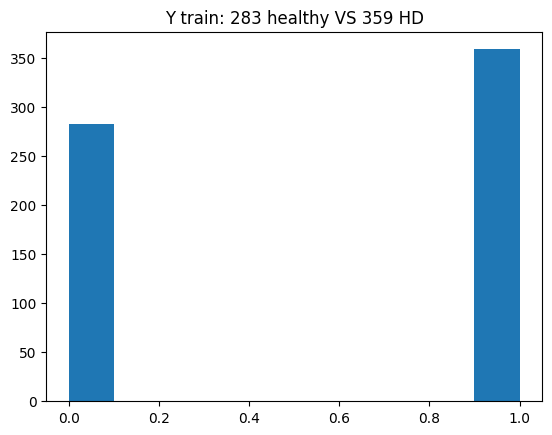

In [ ]:
print(y_train.value_counts())
plt.hist(y_train)
plt.title("Y train: 283 healthy VS 359 HD")
plt.show()

SVM with Hyper-parameter tuning


 Exhaustive Grid Search

In [ ]:
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report
from sklearn.svm import SVC
from sklearn.model_selection import RandomizedSearchCV
# Define a reduced parameter grid for randomized search
param_dist = [
    {'kernel': ['rbf'],
     'gamma': [0.1, 0.01, 0.001],  # fewer options
     'C': [1, 10, 100]},
    {'kernel': ['linear'],
     'C': [1, 10, 100]}
]

# Randomized search: n_iter controls how many parameter combinations are sampled
clf_svm = RandomizedSearchCV(
    SVC(),
    param_distributions=param_dist,
    n_iter=10,              # try 10 random combinations
    cv=3,                   # 3-fold cross-validation instead of 5
    n_jobs=-1,              # use all cores
    verbose=2,
    scoring='balanced_accuracy',
    random_state=42
)

# Fit the model
clf_svm.fit(X_train, y_train)

# Best parameters
print("Best parameters set found on training set:")
print(clf_svm.best_params_)

# Evaluate on test set
y_pred = clf_svm.predict(X_test)
print(classification_report(y_test, y_pred))


Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best parameters set found on training set:
{'kernel': 'linear', 'C': 10}
              precision    recall  f1-score   support

           0       0.83      0.83      0.83       127
           1       0.86      0.85      0.86       149

    accuracy                           0.84       276
   macro avg       0.84      0.84      0.84       276
weighted avg       0.84      0.84      0.84       276



Model Evaluation

Example Accuracy score/ Confusion Matrix:

In [ ]:
import numpy as np
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix

y_predtrain = clf_svm.predict(X_train)

y_pred = clf_svm.predict(X_test)
print("Accuracy -train set-: ", accuracy_score(y_train, y_predtrain))
print("Accuracy -test set-: ", accuracy_score(y_test, y_pred))

confusion_matrix(y_test, y_pred)
print(classification_report(y_test,y_pred))

Accuracy -train set-:  0.8660436137071651
Accuracy -test set-:  0.8442028985507246
              precision    recall  f1-score   support

           0       0.83      0.83      0.83       127
           1       0.86      0.85      0.86       149

    accuracy                           0.84       276
   macro avg       0.84      0.84      0.84       276
weighted avg       0.84      0.84      0.84       276



**xgboost**


In [ ]:
from numpy import loadtxt
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

param_test2 = {
 'max_depth':[3,6,8,10,12],
 'min_child_weight':[3,6,8,10,12],
 'n_estimators':[20,50,100,200,500],
 'gamma':[i/10.0 for i in range(0,5)] ,
 'reg_alpha':[0, 0.001, 0.005, 0.01, 0.05]
}

param_test1 = {
 'max_depth':[3,6,8,10,12],
 'min_child_weight':[3,6,8,10,12],
 'n_estimators':[20,50,100,200],
 }

gsearch1 = GridSearchCV(estimator = XGBClassifier( learning_rate =0.1, n_estimators=140, max_depth=5,
 min_child_weight=1, gamma=0, subsample=0.8, colsample_bytree=0.8,
 objective= 'binary:logistic', nthread=4, scale_pos_weight=1, seed=27),
 param_grid = param_test1, scoring='roc_auc',n_jobs=6,cv=5)

gsearch1.fit(X_train, y_train)

print(gsearch1.best_params_)
print(gsearch1.best_score_)

model=gsearch1

# fit model no training data
#model = XGBClassifier( max_depth=3, min_child_weight=3, n_estimators=200       )

#model.fit(X_train, y_train)
print(model)
# make predictions for test data
y_pred = model.predict(X_test)
predictions = [round(value) for value in y_pred]
# evaluate predictions
accuracy = accuracy_score(y_test, predictions)
print("Accuracy: %.2f%%" % (accuracy * 100.0))

from sklearn.metrics import classification_report

# printing the report
print(classification_report(y_test, y_pred))

confusion_matrix(y_test, y_pred)

{'max_depth': 3, 'min_child_weight': 6, 'n_estimators': 100}
0.9332803105180792
GridSearchCV(cv=5,
             estimator=XGBClassifier(base_score=None, booster=None,
                                     callbacks=None, colsample_bylevel=None,
                                     colsample_bynode=None,
                                     colsample_bytree=0.8, device=None,
                                     early_stopping_rounds=None,
                                     enable_categorical=False, eval_metric=None,
                                     feature_types=None, feature_weights=None,
                                     gamma=0, grow_policy=None,
                                     importance_type=None,
                                     interaction_constraints=None,
                                     le...None,
                                     max_cat_threshold=None,
                                     max_cat_to_onehot=None,
                                     ma

array([[106,  21],
       [ 24, 125]])

**xgboost - Training Accuracy: 83.7%**

In [ ]:
import numpy as np
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix

y_pred = model.predict(X_test)
print(accuracy_score(y_test, y_pred))

#confusion_matrix(y_test, y_pred)

0.8369565217391305


**xgboost - Testing Accuracy: 83.69%**

In [ ]:
from sklearn.metrics import classification_report
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.82      0.83      0.82       127
           1       0.86      0.84      0.85       149

    accuracy                           0.84       276
   macro avg       0.84      0.84      0.84       276
weighted avg       0.84      0.84      0.84       276



**Random forest and important features**

In [ ]:
!pip3 install scikit-plot

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, roc_auc_score
from sklearn.metrics import ConfusionMatrixDisplay, precision_score, recall_score, f1_score, classification_report
from sklearn.metrics import roc_curve,  auc
#from scikitplot.metrics import plot_roc_curve,plot_precision_recall_curve
from sklearn.metrics import precision_recall_curve, average_precision_score
from sklearn.model_selection import cross_val_score


rfc = RandomForestClassifier(
                            # n_estimators=250,
                            # max_depth=18,
                             max_features='sqrt', random_state=0,
                             bootstrap=True,
                             class_weight = "balanced")
rfc.fit(X_train, y_train)
y_pred = rfc.predict(X_test)
roc_auc_score(y_test, y_pred)

print('confusion matrix = \n', confusion_matrix(y_test, y_pred, labels=[1, 0]))
print('\n')
print('accuracy = ', accuracy_score(y_test, y_pred))
print('precision = ', precision_score(y_test, y_pred))
print('recall = ', recall_score(y_test, y_pred))
print('f1 score = ', f1_score(y_test, y_pred))
print('\n')

from sklearn.metrics import classification_report
print(classification_report(y_test,y_pred))

confusion matrix = 
 [[130  19]
 [ 20 107]]


accuracy =  0.8586956521739131
precision =  0.8666666666666667
recall =  0.87248322147651
f1 score =  0.8695652173913043


              precision    recall  f1-score   support

           0       0.85      0.84      0.85       127
           1       0.87      0.87      0.87       149

    accuracy                           0.86       276
   macro avg       0.86      0.86      0.86       276
weighted avg       0.86      0.86      0.86       276



**Random Forest - Acc: 86%**

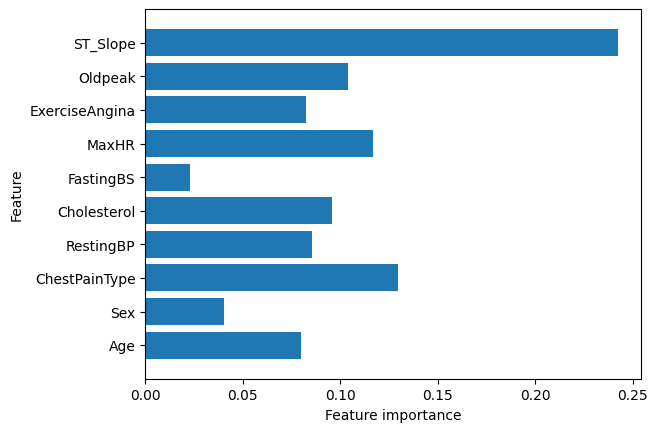

In [ ]:
def plot_feature_importances_HD(model,XX):
    n_features = XX.shape[1]
    plt.barh(np.arange(n_features), model.feature_importances_, align='center')
    plt.yticks(np.arange(n_features), XX.columns)
    plt.xlabel("Feature importance")
    plt.ylabel("Feature")
    plt.ylim(-1, n_features)

plot_feature_importances_HD(rfc,X_train)

--> The feature importance analysis using the Random Forest classifier revealed that ST_Slope, ExerciseAngina, Oldpeak, and MaxHR contributed most strongly to the predictive performance of the model. These variables carry the highest information gain, indicating that they play a major role in distinguishing patients with and without heart disease.

In [ ]:
from sklearn.linear_model import LogisticRegression

#LRE = LogisticRegression()
C1=10
LRE = LogisticRegression(C=C1, solver='liblinear', penalty="l1")

LRE.fit(X_train, y_train)
y_pred = LRE.predict(X_test)
roc_auc_score(y_test, y_pred)

print('confusion matrix = \n', confusion_matrix(y_test, y_pred, labels=[1, 0]))
print('accuracy = ', accuracy_score(y_test, y_pred))
print('precision = ', precision_score(y_test, y_pred))
print('recall = ', recall_score(y_test, y_pred))
print('f1 score = ', f1_score(y_test, y_pred))
print("\n")

from sklearn.metrics import classification_report
print(classification_report(y_test,y_pred))

confusion matrix = 
 [[126  23]
 [ 24 103]]
accuracy =  0.8297101449275363
precision =  0.84
recall =  0.8456375838926175
f1 score =  0.842809364548495


              precision    recall  f1-score   support

           0       0.82      0.81      0.81       127
           1       0.84      0.85      0.84       149

    accuracy                           0.83       276
   macro avg       0.83      0.83      0.83       276
weighted avg       0.83      0.83      0.83       276



**LogisticRegression - Accuracy: 83%**

> Concluding, to create a predictive model:
    
    1. Load the dataset, preprocess
    2. Feature Selection
    3. Hyperparameter Tuning
    4. Train
    5. Evaluate

# APPENDIX

In [ ]:
# GIA THN FENIA - GIA MELETH -  - CHI^2 TEST // LYSI 2
# TO PARAKATW TO KANW GIA NA EPIVEVAIWSW POIES STHLES EXOYN KALO P-VALUE WSTE NA KSEXORISW POIES STILES MENOYN K POIES EINAI AXRHSTES
target = 'HeartDisease'

# 1. Identify features
continuous_features = df.select_dtypes(include=['int64','float64']).columns.tolist()
continuous_features.remove(target)

categorical_features = df.select_dtypes(include=['object', 'bool', 'category']).columns.tolist()

# 2. Dictionaries to store results
feature_results = []

# 3. Continuous features: T-Test or Kruskal-Wallis
for feature in continuous_features:
    group0 = df[df[target] == 0][feature]
    group1 = df[df[target] == 1][feature]

    # Parametric: T-Test
    stat, p_value = ttest_ind(group0, group1, equal_var=False)

    # Non-parametric: Kruskal-Wallis (uncomment if data is not normal)
    # stat, p_value = kruskal(group0, group1)

    feature_results.append({
        'Feature': feature,
        'Type': 'Continuous',
        'p-value': p_value,
        'Keep': p_value <= 0.05
    })

# 4. Categorical features: Chi-square test
for feature in categorical_features:
    contingency_table = pd.crosstab(df[feature], df[target])
    stat, p_value, dof, expected = chi2_contingency(contingency_table)

    feature_results.append({
        'Feature': feature,
        'Type': 'Categorical',
        'p-value': p_value,
        'Keep': p_value <= 0.05
    })

# 5. Convert results to DataFrame
results_df = pd.DataFrame(feature_results)
keep_features = results_df[results_df['Keep'] == True]['Feature'].tolist()
drop_features = results_df[results_df['Keep'] == False]['Feature'].tolist()

# 6. Results
print("Features to keep:\n", keep_features)
print("\nFeatures to drop:\n", drop_features)
print("\nFull results:\n", results_df.sort_values('p-value'))

In [ ]:
from sklearn.linear_model import LogisticRegression
# GIA MELETI THS FENIAS - TO IDIO APOTELESMA PAIRNW ME VSM (bl parapanw) KATHWS APODEIXTIKE GIA 3H FORA SYNEXOMENA OTI
# H STHLH RestingBP EINAI AXRHSTH GIA TO MONTELO MOY.
model = LogisticRegression(max_iter=1000)

# Create RFE object to select top 5 features
rfe = RFE(estimator=model, n_features_to_select=5)
rfe.fit(X, y)

# Selected features
selected_features = X.columns[rfe.support_]
print("Top 5 features selected by RFE:", selected_features)

# Feature ranking
ranking = pd.Series(rfe.ranking_, index=X.columns).sort_values()
print("Feature ranking:\n", ranking)